
# Snow Avalanches as a Critical Phenomenon

A snowpack doesn't fail gradually. Snow accumulates quietly for days,
then a single extra snowflake somewhere can trigger a slide that carries
away a slope's worth of snowpack, or nothing at all — there's no way to
tell which from the snowflake alone. Avalanche sizes, like wildfire
sizes, follow a **power law**: no typical avalanche size, just fewer and
fewer of them as size grows.

This is the second demo in this repository's self-organized criticality
(SOC) series (see `../../wildfire/` for the first, forest fires). Where
the forest-fire model needed a carefully tuned separation of two
probabilities to reach criticality, this one is built from the
**original** SOC toy model — the Bak-Tang-Wiesenfeld (BTW) sandpile
(1987) — reframed here as snow loading a slope until it slides. It
self-organizes to a critical state almost regardless of parameters,
which makes it a good second data point for the same two hallmarks:

1. **Power-law distributed avalanche sizes.**
2. **1/f-type ("colored") noise** in the global release-activity signal.

As with the wildfire notebook, both are checked with real statistical
tests (a maximum-likelihood power-law fit plus a likelihood-ratio test
against an exponential, and a properly log-binned spectral fit) rather
than eyeballed straight lines — and, in the spirit of that notebook, the
numbers are reported honestly even where they complicate the textbook
story.


In [1]:

import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent.parent))  # -> toySystems/

import numpy as np
from IPython.display import Video, display

from common import powerlaw, spectral
from common.viz import set_style, save_fig, PALETTE, ACCENT, ACCENT2, MUTED
from sandpile.model import SandpileModel
from sandpile.viz import animate_grid, show_grid

import matplotlib.pyplot as plt

set_style()

FIG_DIR = Path("../figures")
VID_DIR = Path("../videos")
DATA_DIR = Path("../data")
for d in (FIG_DIR, VID_DIR, DATA_DIR):
    d.mkdir(exist_ok=True, parents=True)

RNG_SEED = 20260911



## The model

Every site on an $L \times L$ grid holds an integer load $z(i,j)$ — think
of it as local slope steepness from packed snow. The dynamics are just
two rules:

1. **Drive:** drop one unit of snow on a uniformly random site.
2. **Relax:** any site with $z \geq z_c$ (here $z_c = 4$) releases —
   it drops by $z_c$ and each of its (up to four) neighbors gains one
   unit. If that pushes a neighbor over threshold too, it releases on
   the next sweep, and so on until every site is stable again. Snow that
   would leave the grid's edge is simply gone (open boundaries) — the
   base of the mountain, dissipating load rather than reflecting it back.

Critically, steps 1 and 2 are never interleaved: **the entire avalanche
finishes before the next grain falls.** That's a much stronger, cleaner
separation of time scales than the wildfire model's $f \ll p$, and it's
also *exact* rather than probabilistic — nothing to tune, and no risk of
one avalanche merging into the next. Given that, this model can only
approach one thing: a stationary, marginally stable slope profile that
sits right at the point where the next grain could be a non-event or
could be a slope-wide slide, and there's no way to know which in advance.


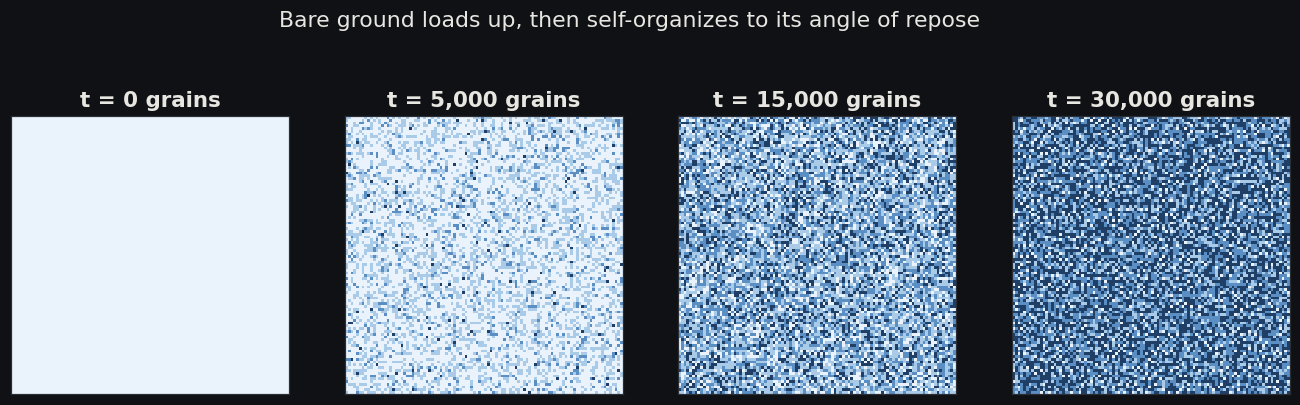

In [2]:

# start from bare ground (no snow at all) so the buildup is visible, rather
# than starting mid-way through with a random load
model = SandpileModel(L=100, initial="zeros", seed=RNG_SEED)

fig, axes = plt.subplots(1, 4, figsize=(15, 4))
checkpoints = [0, 5000, 15000, 30000]
snaps = {}
for target in checkpoints:
    while model.t < target:
        model.step()
    snaps[target] = model.render_code()

for ax, t in zip(axes, checkpoints):
    show_grid(ax, snaps[t], title=f"t = {t:,} grains")

fig.suptitle("Bare ground loads up, then self-organizes to its angle of repose",
             y=1.05, color="#e8e6e1")
save_fig(fig, FIG_DIR / "self_organization_snapshots.png")
plt.show()



## Watching it run

Most snowflakes land and do nothing. Every so often one lands in exactly
the wrong place and the slope lets go — visible below as a flash of
bright red spreading across the grid, and as a spike in the strip chart
underneath. The dark-blue regions are the most heavily loaded, closest
to their next release.


In [3]:

vid_model = SandpileModel(L=80, seed=RNG_SEED + 1)
vid_model.run(3000)  # reach the statistically stationary state first

frames, activity = vid_model.run_frames(100)
video_path = animate_grid(
    frames, VID_DIR / "steady_state_dynamics.mp4", fps=15, dpi=100,
    title="Sandpile SOC: steady-state dynamics", activity=activity,
)
display(Video(str(video_path), embed=True, html_attributes="loop autoplay muted controls"))



## Anatomy of a single avalanche

A close-up on one large release: a single grain destabilizes one site,
which destabilizes its neighbors, which destabilize theirs — a wave of
toppling that spreads, branches, and eventually exhausts itself once the
local load drops back below threshold everywhere.


In [4]:

av_model = SandpileModel(L=80, seed=RNG_SEED + 2)
av_model.run(3000)
av_frames, av_activity = av_model.capture_avalanche(min_size=2000, max_grains=300_000)

print(f"captured avalanche: {av_activity[av_activity > 0].sum():,} topples "
      f"over {(av_activity > 0).sum()} relaxation sweeps, {len(av_frames)} frames total")

av_video_path = animate_grid(
    av_frames, VID_DIR / "single_avalanche.mp4", fps=10, dpi=100,
    title="Anatomy of one avalanche", activity=av_activity,
)
display(Video(str(av_video_path), embed=True, html_attributes="loop autoplay muted controls"))


captured avalanche: 3,814 topples over 265 relaxation sweeps, 268 frames total



## Hallmark #1 — power-law distributed avalanche sizes

Now the real experiment: drop a few hundred thousand grains and record,
for every avalanche that results, its **size** (total topples), its
**area** (distinct sites that released at least once — a site can
release more than once in a single avalanche), and the global
**activity** time series needed for the noise spectrum later.


In [5]:

%%time
sim = SandpileModel(L=64, seed=RNG_SEED + 3)
result = sim.run(n_grains=150_000, progress=True)

print(f"{result.n_avalanches:,} avalanches recorded")
print(f"mean load: {result.mean_load[-30_000:].mean():.3f} / {sim.z_c} "
      f"= {result.mean_load[-30_000:].mean() / sim.z_c:.3f} "
      "(the known theoretical value for the 2D BTW stationary state is 2.125/4 = 0.531)")

np.savez(DATA_DIR / "sandpile_long_run.npz",
         activity=result.activity, mean_load=result.mean_load,
         avalanche_sizes=result.avalanche_sizes,
         avalanche_durations=result.avalanche_durations,
         avalanche_areas=result.avalanche_areas)


dropping grains:   0%|          | 0/150000 [00:00<?, ?it/s]

65,240 avalanches recorded
mean load: 2.103 / 4 = 0.526 (the known theoretical value for the 2D BTW stationary state is 2.125/4 = 0.531)
CPU times: user 2min 55s, sys: 2.31 s, total: 2min 58s
Wall time: 2min 57s



A first pass, fitting with the same defaults used for the wildfire
model, is worth being upfront about: it doesn't immediately look clean.


In [6]:

fit_default = powerlaw.fit_power_law(result.avalanche_sizes)
print("fit using the whole-tail default:", fit_default)
print(f"likelihood-ratio R = {fit_default.loglik_ratio_exp:.1f} "
      f"-> {'favors' if fit_default.loglik_ratio_exp > 0 else 'does NOT favor'} a power law here.")


fit using the whole-tail default: PowerLawFit(alpha=1.8618913818361358, xmin=331, ks_distance=0.1173651115249158, n_tail=13641, loglik_ratio_exp=-527.2192950297031, p_value_exp=3.5153902011586524e-10)
likelihood-ratio R = -527.2 -> does NOT favor a power law here.



That's a real, well-documented feature of the 2D BTW sandpile, not a
bug: unlike the forest-fire model's fire sizes, the *full* avalanche-size
distribution has known curvature — different apparent scaling in the
small-avalanche bulk versus the large-avalanche tail (see e.g. Priezzhev
et al. on multiscaling in the BTW model). A single power law only
describes the tail. So — same rule as before: check it explicitly rather
than assume it, this time by scanning how the fit changes as we require
the candidate cutoff $x_{min}$ to retain less and less of the small-event
bulk.


In [7]:

fractions = [0.3, 0.2, 0.1, 0.05, 0.03]
scan = [(f, powerlaw.fit_power_law(result.avalanche_sizes, min_tail_fraction=f)) for f in fractions]
for f, fit in scan:
    favors = "favors power law" if fit.loglik_ratio_exp > 0 and fit.p_value_exp < 0.05 else "favors exponential"
    print(f"min_tail_fraction={f:<5} xmin={fit.xmin:<6} alpha={fit.alpha:.2f}  "
          f"n_tail={fit.n_tail:<6} R={fit.loglik_ratio_exp:8.1f}  -> {favors}")

fit = powerlaw.fit_power_law(result.avalanche_sizes, min_tail_fraction=0.05)
print(f"\nkeeping the largest ~5% of avalanches: {fit}")


min_tail_fraction=0.3   xmin=67     alpha=1.54  n_tail=25423  R=   809.6  -> favors power law
min_tail_fraction=0.2   xmin=331    alpha=1.86  n_tail=13641  R=  -527.2  -> favors exponential
min_tail_fraction=0.1   xmin=1005   alpha=2.39  n_tail=6554   R=   526.5  -> favors power law
min_tail_fraction=0.05  xmin=1647   alpha=2.76  n_tail=3812   R=   639.1  -> favors power law
min_tail_fraction=0.03  xmin=1863   alpha=2.88  n_tail=3250   R=   640.8  -> favors power law



keeping the largest ~5% of avalanches: PowerLawFit(alpha=2.7647439181794944, xmin=1647, ks_distance=0.06503871334719447, n_tail=3812, loglik_ratio_exp=639.0587120169439, p_value_exp=0.0)


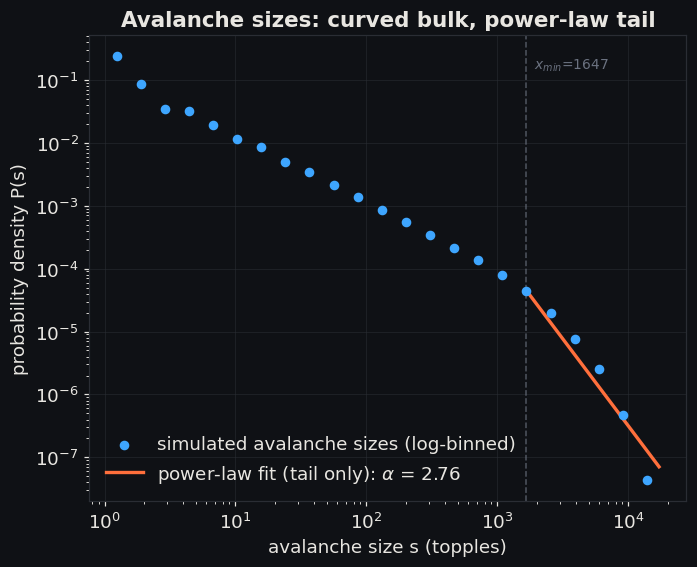

In [8]:

centers, dens = powerlaw.log_binned_histogram(result.avalanche_sizes)

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.scatter(centers, dens, s=28, color=ACCENT2, zorder=3, label="simulated avalanche sizes (log-binned)")

c0 = centers[centers >= fit.xmin][0]
d0 = dens[centers >= fit.xmin][0]
xs = np.logspace(np.log10(fit.xmin), np.log10(result.avalanche_sizes.max()), 50)
ax.plot(xs, d0 * (xs / c0) ** (-fit.alpha), color=ACCENT, lw=2.2,
        label=fr"power-law fit (tail only): $\alpha$ = {fit.alpha:.2f}")
ax.axvline(fit.xmin, color=MUTED, ls="--", lw=1, alpha=0.7)
ax.text(fit.xmin, dens.max(), f"  $x_{{min}}$={fit.xmin}", color=MUTED, fontsize=9, va="top")

ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("avalanche size s (topples)")
ax.set_ylabel("probability density P(s)")
ax.set_title("Avalanche sizes: curved bulk, power-law tail")
ax.legend(frameon=False)
save_fig(fig, FIG_DIR / "avalanche_size_powerlaw.png")
plt.show()



### Bonus: avalanche area

Area — the number of *distinct* sites a release touches, regardless of
how many times each one topples — is a second, independent way to size
an avalanche. It shows the same qualitative pattern.


PowerLawFit(alpha=3.8019738673508177, xmin=1271, ks_distance=0.11992190142610648, n_tail=3737, loglik_ratio_exp=1414.9357543559963, p_value_exp=0.0)
likelihood-ratio test favors a power law (R = 1414.9, p = 0).


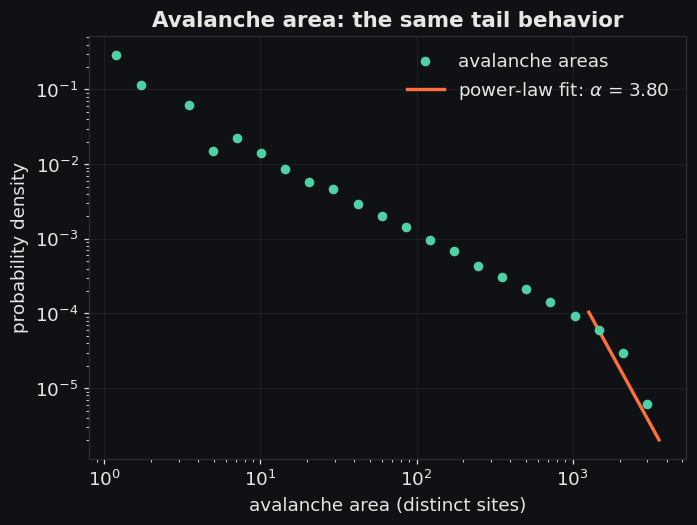

In [9]:

area_fit = powerlaw.fit_power_law(result.avalanche_areas, min_tail_fraction=0.05)
print(area_fit)
favors = area_fit.loglik_ratio_exp > 0 and area_fit.p_value_exp < 0.05
print(f"likelihood-ratio test {'favors' if favors else 'does not favor'} a power law "
      f"(R = {area_fit.loglik_ratio_exp:.1f}, p = {area_fit.p_value_exp:.2g}).")

centers_a, dens_a = powerlaw.log_binned_histogram(result.avalanche_areas)
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(centers_a, dens_a, s=28, color=PALETTE[2], zorder=3, label="avalanche areas")
c0a = centers_a[centers_a >= area_fit.xmin][0]
d0a = dens_a[centers_a >= area_fit.xmin][0]
xs_a = np.logspace(np.log10(area_fit.xmin), np.log10(result.avalanche_areas.max()), 50)
ax.plot(xs_a, d0a * (xs_a / c0a) ** (-area_fit.alpha), color=ACCENT, lw=2.2,
        label=fr"power-law fit: $\alpha$ = {area_fit.alpha:.2f}")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("avalanche area (distinct sites)")
ax.set_ylabel("probability density")
ax.set_title("Avalanche area: the same tail behavior")
ax.legend(frameon=False)
save_fig(fig, FIG_DIR / "avalanche_area_powerlaw.png")
plt.show()



## Hallmark #2 — 1/f-type ("colored") noise

As with the wildfire model, take the global activity — grains toppling
per tick, summed over the whole grid — and look at its power spectrum.
A truly random process spreads its power flat across every frequency
(white noise, $\beta \approx 0$); a random walk concentrates it at low
frequencies (brown noise, $\beta \approx 2$); a scale-free process with
no characteristic time constant sits in between. The same low-frequency
knee (the pile's overall regeneration time) and high-frequency floor
(single-grain shot noise) bound where that scaling actually holds, so we
fit the slope only in between, exactly as before.


fitted spectral slope beta = 1.64 -> red / brown noise (beta ~ 2): a random walk, strongly autocorrelated


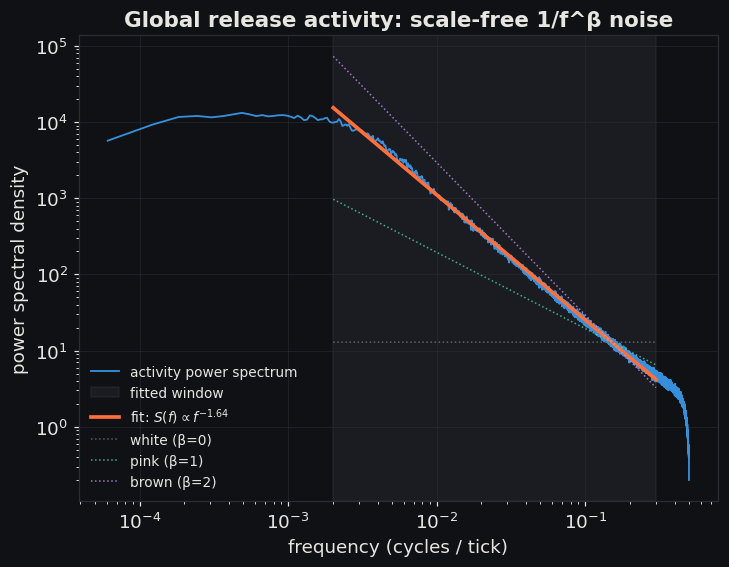

In [10]:

freqs, psd = spectral.welch_psd(result.activity)
FIT_FMIN, FIT_FMAX = 0.002, 0.3
spec_fit = spectral.fit_spectral_slope(freqs, psd, fmin=FIT_FMIN, fmax=FIT_FMAX)
print(f"fitted spectral slope beta = {spec_fit.beta:.2f} -> {spectral.classify_noise_color(spec_fit.beta)}")

fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.loglog(freqs[1:], psd[1:], color=ACCENT2, lw=1.2, alpha=0.85, label="activity power spectrum")
ax.axvspan(FIT_FMIN, FIT_FMAX, color=MUTED, alpha=0.12, label="fitted window")

f_ref = spec_fit.freqs
scale = 10 ** spec_fit.intercept
ax.loglog(f_ref, scale * f_ref ** (-spec_fit.beta), color=ACCENT, lw=2.4,
          label=fr"fit: $S(f) \propto f^{{-{spec_fit.beta:.2f}}}$")

f_anchor = f_ref[len(f_ref) // 2]
y_anchor = scale * f_anchor ** (-spec_fit.beta)
for beta_ref, label, color in [(0, "white (β=0)", MUTED), (1, "pink (β=1)", PALETTE[2]), (2, "brown (β=2)", PALETTE[3])]:
    ax.loglog(f_ref, y_anchor * (f_ref / f_anchor) ** (-beta_ref),
              color=color, lw=1, ls=":", alpha=0.8, label=label)

ax.set_xlabel("frequency (cycles / tick)")
ax.set_ylabel("power spectral density")
ax.set_title("Global release activity: scale-free 1/f^β noise")
ax.legend(frameon=False, fontsize=9)
save_fig(fig, FIG_DIR / "activity_power_spectrum.png")
plt.show()



This exponent is closer to textbook pink noise than the wildfire model's
was, and — reassuringly, given how much that earlier number moved around
under different fitting windows — it's noticeably more stable here
across reasonable choices of `FIT_FMIN`/`FIT_FMAX`. That stability itself
is worth something: the original 1987 BTW paper's own claim of "1/f
noise" in the sandpile has been disputed and refined for decades since
(see e.g. Jensen, *Self-Organized Criticality*), and the honest summary
is what both of our simulations agree on regardless of the exact
exponent: **the activity spectrum is a power law, clearly not white, with
no characteristic frequency** — not that any particular $\beta$ is the
universal signature of every SOC system.



## Self-organization in action: load needs no tuning

The mean load was never set — it settles on its own to a stationary
value close to the known theoretical result for this model, and stays
there.


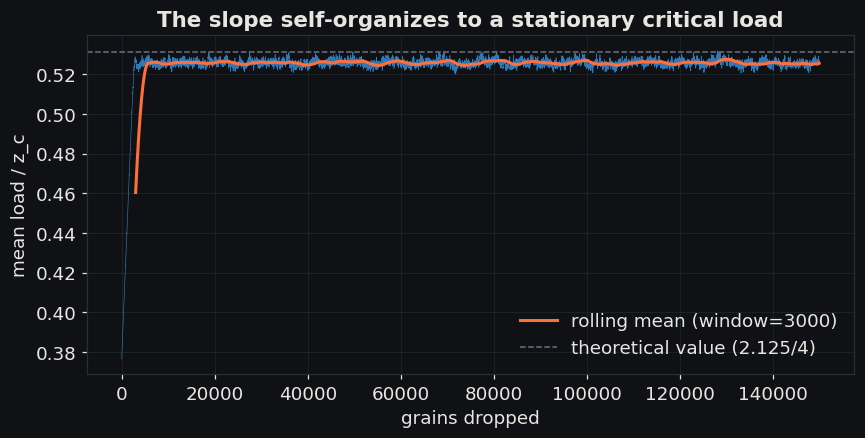

In [11]:

fig, ax = plt.subplots(figsize=(9, 4))
t = np.arange(len(result.mean_load))
ax.plot(t, result.mean_load / sim.z_c, color=ACCENT2, lw=0.4, alpha=0.7)
window = 3000
rolling = np.convolve(result.mean_load / sim.z_c, np.ones(window) / window, mode="valid")
ax.plot(t[window - 1:], rolling, color=ACCENT, lw=2, label=f"rolling mean (window={window})")
ax.axhline(2.125 / 4, color=MUTED, ls="--", lw=1, label="theoretical value (2.125/4)")
ax.set_xlabel("grains dropped")
ax.set_ylabel("mean load / z_c")
ax.set_title("The slope self-organizes to a stationary critical load")
ax.legend(frameon=False)
save_fig(fig, FIG_DIR / "load_self_organization.png")
plt.show()



## Summary dashboard


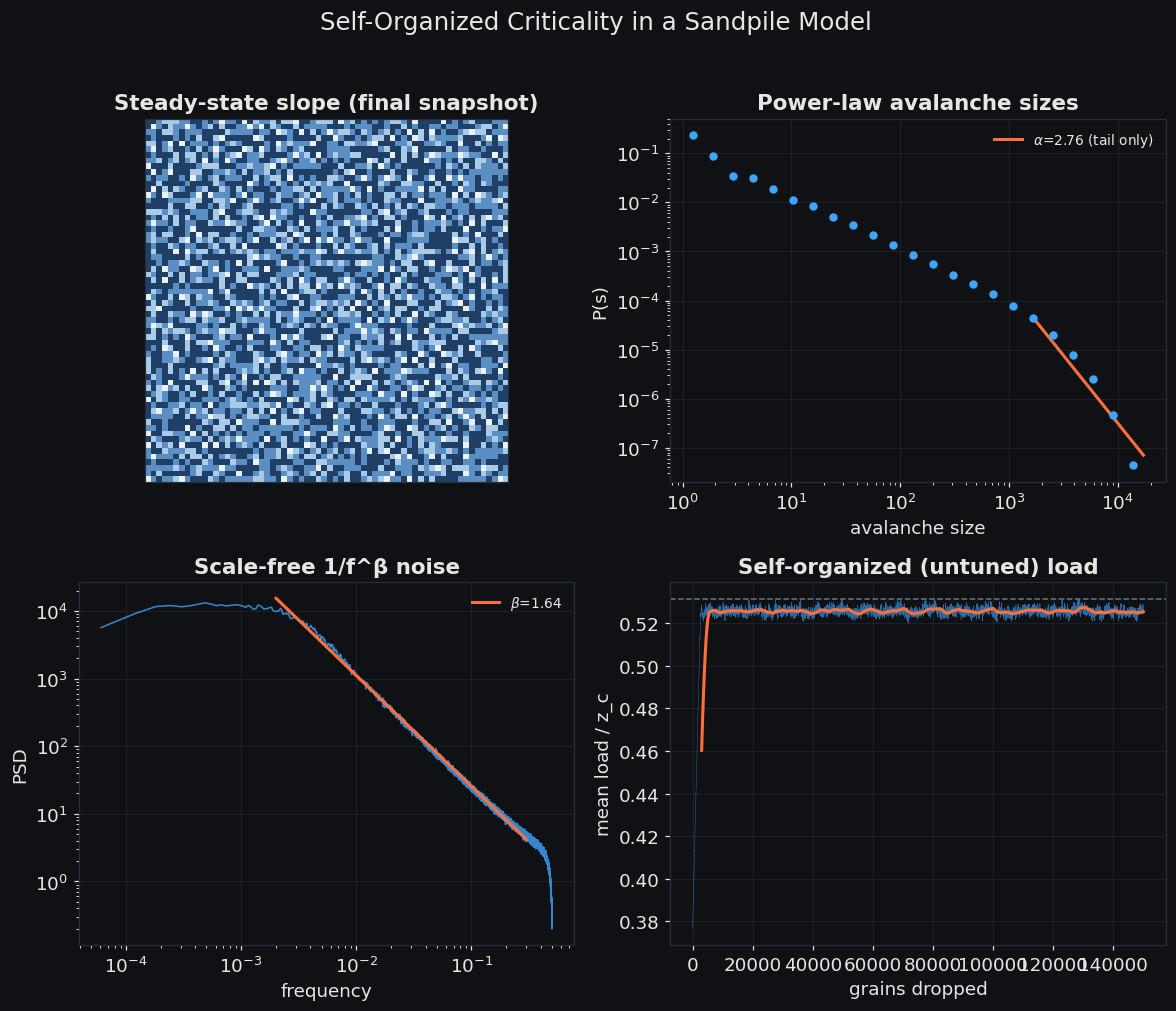

In [12]:

fig, axes = plt.subplots(2, 2, figsize=(11, 9))

show_grid(axes[0, 0], sim.render_code(), title="Steady-state slope (final snapshot)")

ax = axes[0, 1]
ax.scatter(centers, dens, s=20, color=ACCENT2, zorder=3)
ax.plot(xs, d0 * (xs / c0) ** (-fit.alpha), color=ACCENT, lw=2,
        label=fr"$\alpha$={fit.alpha:.2f} (tail only)")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("avalanche size"); ax.set_ylabel("P(s)")
ax.set_title("Power-law avalanche sizes")
ax.legend(frameon=False, fontsize=9)

ax = axes[1, 0]
ax.loglog(freqs[1:], psd[1:], color=ACCENT2, lw=1, alpha=0.8)
ax.loglog(f_ref, scale * f_ref ** (-spec_fit.beta), color=ACCENT, lw=2,
          label=fr"$\beta$={spec_fit.beta:.2f}")
ax.set_xlabel("frequency"); ax.set_ylabel("PSD")
ax.set_title("Scale-free 1/f^β noise")
ax.legend(frameon=False, fontsize=9)

ax = axes[1, 1]
ax.plot(t, result.mean_load / sim.z_c, color=ACCENT2, lw=0.3, alpha=0.6)
ax.plot(t[window - 1:], rolling, color=ACCENT, lw=2)
ax.axhline(2.125 / 4, color=MUTED, ls="--", lw=1)
ax.set_xlabel("grains dropped"); ax.set_ylabel("mean load / z_c")
ax.set_title("Self-organized (untuned) load")

fig.suptitle("Self-Organized Criticality in a Sandpile Model", fontsize=16, y=1.02)
fig.tight_layout()
save_fig(fig, FIG_DIR / "soc_dashboard.png")
plt.show()


In [13]:

from IPython.display import Markdown, display

display(Markdown(f'''
## Takeaways

- Two rules — drop a grain, then fully relax before the next one — are
  enough to produce **global scale-invariance**, with nothing tuned to a
  special value. Unlike the wildfire model's $f \\ll p$, here the
  separation of time scales is exact by construction, not a probability
  to calibrate.
- Avalanche sizes are **power-law distributed in their tail**
  ($\\alpha \\approx {fit.alpha:.2f}$ above $x_{{min}}={fit.xmin}$, confirmed
  by a likelihood-ratio test against an exponential), though — unlike the
  wildfire model — the *full* distribution has real, literature-documented
  curvature rather than one clean power law start to finish.
- The global activity signal has a **scale-free 1/f^β spectrum**
  ($\\beta \\approx {spec_fit.beta:.2f}$), clearly non-white and unusually
  stable across different fitting windows.
- The critical load is an **emergent output** of the dynamics
  (mean = {result.mean_load[-30_000:].mean() / sim.z_c:.3f}, vs. a
  theoretical value of {2.125/4:.3f}), not an input.
'''))



## Takeaways

- Two rules — drop a grain, then fully relax before the next one — are
  enough to produce **global scale-invariance**, with nothing tuned to a
  special value. Unlike the wildfire model's $f \ll p$, here the
  separation of time scales is exact by construction, not a probability
  to calibrate.
- Avalanche sizes are **power-law distributed in their tail**
  ($\alpha \approx 2.76$ above $x_{min}=1647$, confirmed
  by a likelihood-ratio test against an exponential), though — unlike the
  wildfire model — the *full* distribution has real, literature-documented
  curvature rather than one clean power law start to finish.
- The global activity signal has a **scale-free 1/f^β spectrum**
  ($\beta \approx 1.64$), clearly non-white and unusually
  stable across different fitting windows.
- The critical load is an **emergent output** of the dynamics
  (mean = 0.526, vs. a
  theoretical value of 0.531), not an input.



### Where this fits in `toySystems/`

- `sandpile/model.py` — the abelian sandpile automaton.
- `sandpile/viz.py` — load-grid-to-video rendering, reusing
  `common.viz.animate_grid_with_activity` (the same generic renderer
  `wildfire/viz.py` uses, just with its own colormap).
- Both hallmark checks reuse `common/powerlaw.py` and
  `common/spectral.py` completely unchanged from the wildfire notebook —
  they only ever see arrays of event sizes or an activity time series,
  never anything wildfire- or sandpile-specific.

Comparing the two demos side by side is itself a small lesson in what
"self-organized criticality" does and doesn't promise: both systems
robustly show power-law event sizes and a non-white, scale-free activity
spectrum, but the *exact* exponents — and even whether a single power law
describes the whole distribution or just its tail — are model-specific
details, not universal constants. The next system in this series
(an Ising model quenched near its critical temperature, a branching
neuronal-avalanche model, ...) should be expected to add its own such
wrinkle rather than simply replay these same two numbers.
